# Evaluate Posterior Density Estimator

In [39]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pickle
import os

from omegaconf import OmegaConf
from multiprocessing import Pool

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior

import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config, binding_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config, generate_fret_prior_from_config
from utils import eval_free_energy_from_config, eval_force_from_config

## Configuration

In [40]:
# Paths
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/test_set/2026-04-15/15-54-42/"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ground-truth parameters (logD, spline_knots[num_knots], R0, kD, photophysics[8])
# Set explicit values, or leave as None to sample from the prior
true_params = torch.tensor([-0.1, -3.0, -1.5, -0.0, 1.5, 3.0, 5.5, 400.00, 0.0100, 0.01000, 0.9500, 0.9500, 0.9000, 0.9000, 0.1000, 0.1000], dtype=torch.float64)
#true_params = torch.tensor([-0.25, -3.0, -1.5, 0.5, 1.5, 3.0, 5.5, 100.0, 0.02, 0.02, 0.85, 0.85, 0.95, 0.95, 0.05, 0.05], dtype=torch.float64)

# Observation settings
n_observations = 10
n_simulations_pool = 100

# Posterior sampling
num_posterior_samples = 10000
posterior_batch_size = 1000

# MAP estimation
map_num_iter = 500
map_learning_rate = 0.01
map_num_init_samples = 5

## Load Prior, Simulator, and Model

In [41]:
data_cfg_path = cfg_path + "data_config.yaml"

prior_sim = generate_fret_prior_from_config(data_cfg_path, device=device)
prior_posterior = generate_posterior_prior_from_config(data_cfg_path, device=device)
eval_force = eval_force_from_config(data_cfg_path)
eval_free_energy = eval_free_energy_from_config(data_cfg_path)
data_cfg = OmegaConf.load(data_cfg_path)

num_knots = data_cfg.prior.num_knots
theta_dim = num_knots + 2  # [logD, g_0..g_{n-1}, R0]

if true_params is None:
    true_params = prior_sim.sample((1,)).squeeze(0).cpu().double()
    print(f"Sampled true_params ({len(true_params)} dims)")
print(f"  posterior params: {true_params[:theta_dim].numpy().round(3)}")
print(f"  logD={true_params[0]:.3f}, R0={true_params[num_knots+1]:.3f}")

if data_cfg.simulator.mode == "equilibrium":
    fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg_path)
elif data_cfg.simulator.mode == "binding":
    _fret_simulator = binding_simulator_wrapper_from_config(data_cfg_path)

    def fret_simulator(params):
        result = _fret_simulator(params)
        if result is None:
            return None
        trajectory, length = result
        if not torch.is_tensor(trajectory):
            trajectory = torch.from_numpy(trajectory).float()
        T = trajectory.shape[0]
        mask = (torch.arange(T) < length).float().unsqueeze(-1)
        return torch.cat([trajectory, mask], dim=-1)

  posterior params: [-0.1 -3.  -1.5 -0.   1.5  3.   5.5]
  logD=-0.100, R0=5.500


In [42]:
assert prior_sim.log_prob(true_params.to(device)).item() > -np.inf, "Ground-truth parameters have zero prior probability under the simulation prior."

In [43]:
try:
    with open(cfg_path + "npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)
except FileNotFoundError:
    with open(cfg_path + "last_npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)

density_estimator = density_estimator.to(device)
density_estimator.eval();

In [44]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

def _init_worker():
    np.random.seed(os.getpid())

## Ground-Truth Free Energy

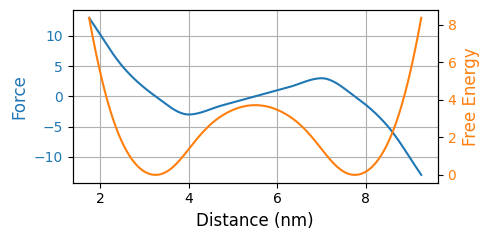

In [45]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (data_cfg.prior.num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(data_cfg.simulator.x_min - x_plot_margin, data_cfg.simulator.x_max + x_plot_margin, 500)

fig, ax1 = plt.subplots(figsize=(5, 2.5), sharex=True)

x, y_force = eval_force(
    params=true_params,
    x_eval=x_eval,
)
ax1.plot(x, y_force, color='tab:blue', label='Force')
ax1.set_xlabel('Distance (nm)', fontsize=12)
ax1.set_ylabel('Force', color='tab:blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid()

ax2 = ax1.twinx()
x, y_free_energy = eval_free_energy(
    params=true_params,
    x_eval=x_eval,
)
ax2.plot(x, y_free_energy - np.min(y_free_energy), color='tab:orange', label='Free Energy')
ax2.set_ylabel('Free Energy', color='tab:orange', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.tight_layout()

## Simulate Observations

In [46]:
with Pool(processes=24, initializer=_init_worker) as pool:
    raw = pool.map(fret_simulator, [true_params] * n_simulations_pool)
results = [r for r in raw if r is not None][:n_observations]
observation = torch.stack(results).unsqueeze(0)  # (1, N, T, C)
print(f"Observation shape: {observation.shape}")

Observation shape: torch.Size([1, 10, 4300, 3])


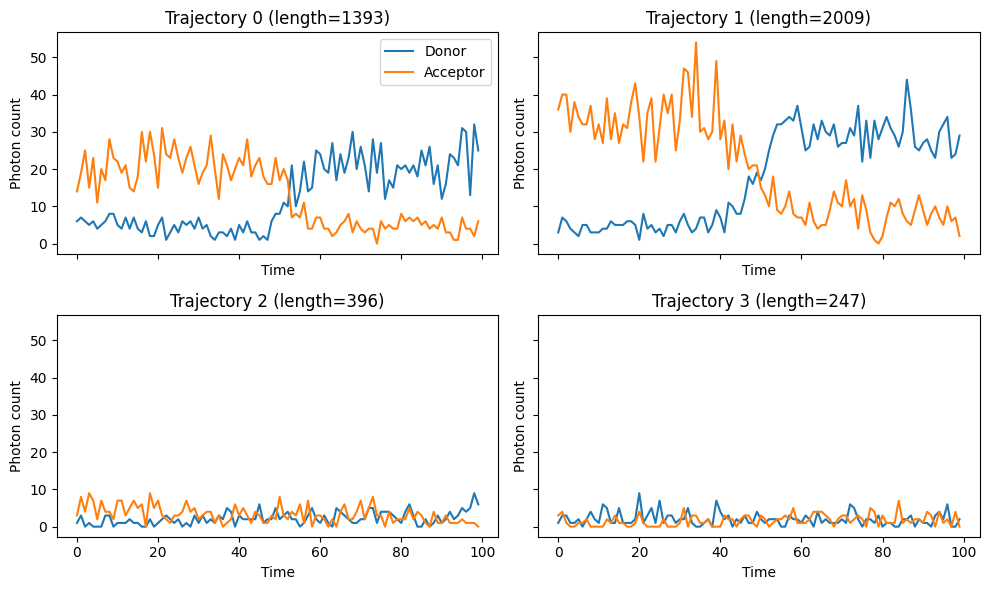

In [47]:
idxs = [0, 1, 2, 3][:observation.shape[1]]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for ax, idx in zip(axes.ravel(), idxs):
    trace = observation[0, idx]  # (T, C)
    # For binding mode, use mask channel to determine valid length
    if trace.shape[-1] == 3:
        length = int(trace[:, 2].sum().item())
    else:
        length = trace.shape[0]
    ax.plot(bin_along_time(trace[:length, 0].numpy(), n_bins=100), label="Donor")
    ax.plot(bin_along_time(trace[:length, 1].numpy(), n_bins=100), label="Acceptor")
    ax.set_title(f"Trajectory {idx} (length={length})")
    ax.set_ylabel("Photon count")
    ax.set_xlabel("Time")

axes[0, 0].legend()
plt.tight_layout()

## Posterior Inference

In [48]:
posterior = DirectPosterior(density_estimator, prior=prior_posterior)
obs = observation.to(device)

samples = posterior.sample(
    (num_posterior_samples,),
    x=obs,
    max_sampling_batch_size=posterior_batch_size,
).cpu()

print(f"Samples shape: {samples.shape}  (expected: [{num_posterior_samples}, {theta_dim}])")

10255it [00:00, 34774.39it/s]                          

Samples shape: torch.Size([10000, 7])  (expected: [10000, 7])


In [49]:
posterior.set_default_x(obs)
map_estimate = posterior.map(
    num_iter=map_num_iter,
    num_init_samples=map_num_init_samples,
    learning_rate=map_learning_rate,
    show_progress_bars=True,
    force_update=True,
)

100%|██████████| 5/5 [00:00<00:00, 205.57it/s]


 Optimizing MAP estimate. Iterations: 265 / 500. Performance in iteration 260: -2.67 (= unnormalized log-prob). Press Ctrl-C to interrupt.Optimization was interrupted after 265 iterations. 


## Results

/tmp/ipykernel_2654814/2370543092.py:10: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


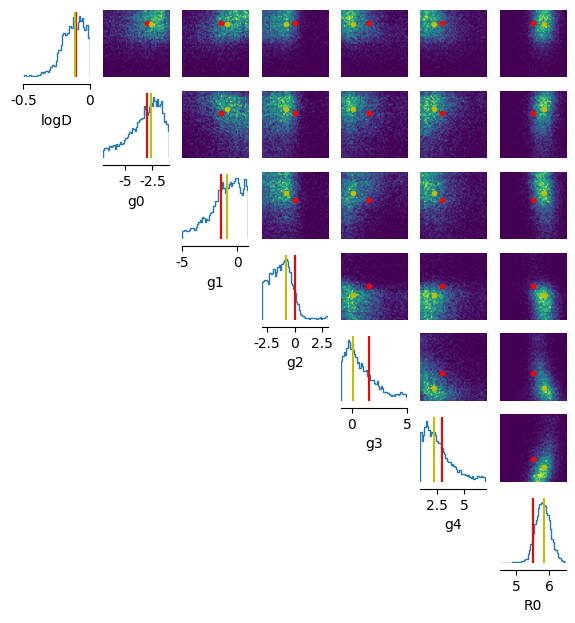

In [50]:
scale = data_cfg.prior.scale
center = list(data_cfg.prior.center) if data_cfg.prior.center is not None else [0.0] * num_knots

limits = (
    [list(data_cfg.prior.logD_lims)]
    + [[c - scale, c + scale] for c in center]
    + [list(data_cfg.prior.R0_lims)]
)

_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=[true_params[:theta_dim].float(), map_estimate[0].cpu()],
    points_offdiag={"markersize": 6},
    points_colors=["r", "y"],
    limits=limits,
    labels=["logD"] + [f"g{i}" for i in range(num_knots)] + ["R0"],
)

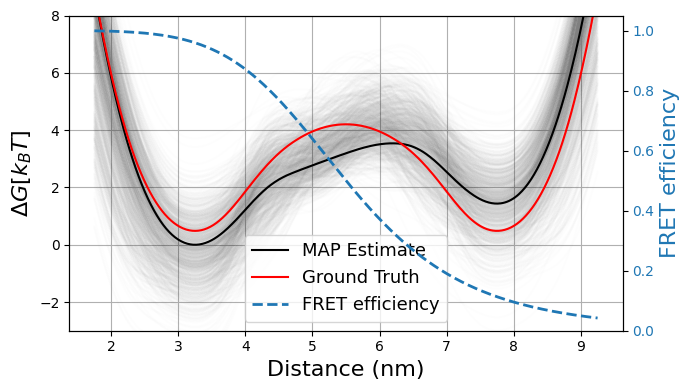

In [51]:
fig, ax1 = plt.subplots(figsize=(7, 4))

# Compute MAP free-energy (reference for alignment)
x, y_map = eval_free_energy(params=map_estimate[0].cpu(), x_eval=x_eval)
y_map_shifted = y_map - y_map.min()

# Free-energy samples — align each to MAP via least-squares vertical shift
# Free energy is defined up to an additive constant, so for each sample we find
# the offset c that minimizes ||y_sample + c - y_map_shifted||^2
# Solution: c = mean(y_map_shifted - y_sample)
for i in range(1000):
    x, y = eval_free_energy(params=samples[i], x_eval=x_eval)
    offset = np.mean(y_map_shifted - y)
    ax1.plot(x, y + offset, color="gray", alpha=0.01)

# MAP free-energy
ax1.plot(x, y_map_shifted, color="black", label="MAP Estimate")

# Ground-truth free-energy (aligned to MAP)
x, y_true = eval_free_energy(params=true_params, x_eval=x_eval)
offset_true = np.mean(y_map_shifted - y_true)
ax1.plot(x, y_true + offset_true, color="r", label="Ground Truth")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
ax1.set_ylim(-3, 8)
ax1.grid()

# Secondary axis: FRET efficiency
ax2 = ax1.twinx()
R0 = float(true_params[num_knots + 1])
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0) ** 6)
E[x_eval <= 0] = np.nan

ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label="FRET efficiency")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=13, loc="best")

plt.tight_layout()